# Unidad 3 - Evaluación de mejoras adicionales

El modelo seleccionado en la Unidad 2 (CNN base con `lr = 1e-4`) **se mantiene como modelo aprobado**. En este notebook se evalúan, frente a ese modelo, dos mejoras adicionales que se definieron al cierre de la Unidad 2 (tabla *Oportunidades de mejora*):

- **Mejora #2. Más épocas y más paciencia en EarlyStopping.** Con `lr = 1e-4` el aprendizaje es más lento: el modelo base alcanzó su mejor `val_loss` entre las épocas 11 y 13 de un máximo de 15, y 20 de las 32 configuraciones del diseño factorial llegaron al límite sin detenerse. Como EarlyStopping restaura los pesos de la mejor época, una paciencia mayor no premia el sobreajuste: solo le da al modelo más margen para seguir bajando la pérdida.
- **Mejora #4. Transfer learning con pesos preentrenados oficiales.** Se usa MobileNetV2 con los pesos de ImageNet que publica Keras (`tf.keras.applications`), ajustada a las 40 clases del caso.

**Protocolo:** el mismo dataset depurado de la Unidad 1, la misma partición 70/15/15 con semilla 42 y los mismos generadores (escala a [0, 1] y volteo horizontal). Se cambia una cosa a la vez y se compara con F1-macro en validación. Solo el mejor experimento se evalúa **una vez** en prueba, para compararlo con el modelo aprobado.

| Experimento | Modelo | Épocas máx. | Paciencia |
|---|---|---|---|
| U3-0 Modelo seleccionado en la U2 (referencia) | CNN base de la Unidad 2 (`lr = 1e-4`) | 15 | 3 |
| U3-1 Más épocas y paciencia | La misma CNN | 40 | 6 |
| U3-2 Transfer learning | MobileNetV2 (ImageNet) + nueva capa de salida | 10 (fase 1) + 40 (fase 2) | 3 + 6 |

In [12]:
# Unidad 3: configuración (no depende de las celdas anteriores)
import os, sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Pipeline de datos del repositorio: misma depuración y partición de las Unidades 1 y 2
if not os.path.isdir("src"):
    if not os.path.isdir("repo"):
        !git clone -q --depth 1 https://github.com/AlejandraIvn/Proyecto_Fundamentos_Redes_Neuronales.git repo
    sys.path.insert(0, "repo")
from src.datos import (IMG_SIZE, SEED, cargar_dataset_modelo, dividir,
                       generador_entrenamiento, generador_evaluacion)
from src.modelo import construir_modelo

PRUEBA_RAPIDA = False              # True = 1 época con ~2,200 imágenes, solo para verificar que todo corre
EPOCAS_U2, PACIENCIA_U2 = 15, 3    # presupuesto de la Unidad 2 (referencia)
EPOCAS_U3, PACIENCIA_U3 = 40, 6    # mejora #2: más épocas y más paciencia
EPOCAS_FASE1 = 10                  # transfer learning, fase 1 (solo la nueva capa de salida)
if PRUEBA_RAPIDA:
    EPOCAS_U2 = EPOCAS_U3 = EPOCAS_FASE1 = 1
    print("MODO PRUEBA RÁPIDA: no usar estos resultados en el informe.")

print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "no disponible")

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [13]:
df_modelo, _ = cargar_dataset_modelo()          # descarga con kagglehub + depuración de la Unidad 1
train_df, val_df, test_df = dividir(df_modelo)  # 70/15/15 estratificada, semilla 42
print(f"Imágenes: {len(df_modelo)} | train: {len(train_df)} | val: {len(val_df)} | test: {len(test_df)}")
print("Misma partición que la Unidad 2 (27605 / 5916 / 5916):",
      (len(train_df), len(val_df), len(test_df)) == (27605, 5916, 5916))
if PRUEBA_RAPIDA:
    train_df = train_df.groupby("articleType").sample(frac=0.08, random_state=SEED)

val_gen = generador_evaluacion(val_df)
test_gen = generador_evaluacion(test_df)
NOMBRES_CLASES = sorted(val_gen.class_indices, key=val_gen.class_indices.get)
NUM_CLASES = len(NOMBRES_CLASES)

Using Colab cache for faster access to the 'fashion-product-images-small' dataset.
Imágenes: 39437 | train: 27605 | val: 5916 | test: 5916
Misma partición que la Unidad 2 (27605 / 5916 / 5916): True
Found 5916 validated image filenames belonging to 40 classes.
Found 5916 validated image filenames belonging to 40 classes.


In [14]:
resultados, historiales, modelos = {}, {}, {}

def entrenar(nombre, modelo, learning_rate, epocas, paciencia):
    """Entrena con EarlyStopping (val_loss, restaura la mejor época) y registra las métricas de validación."""
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate),
                   loss="categorical_crossentropy", metrics=["accuracy"])
    parada = EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True)
    t0 = time.time()
    hist = modelo.fit(generador_entrenamiento(train_df), validation_data=val_gen,
                      epochs=epocas, callbacks=[parada], verbose=2)
    y_pred = modelo.predict(val_gen, verbose=0).argmax(axis=1)
    val_loss = hist.history["val_loss"]
    resultados[nombre] = {
        "val_acc": accuracy_score(val_gen.classes, y_pred),
        "val_F1_macro": f1_score(val_gen.classes, y_pred, average="macro"),
        "val_F1_weighted": f1_score(val_gen.classes, y_pred, average="weighted"),
        "mejor_val_loss": min(val_loss),
        "mejor_epoca": int(np.argmin(val_loss)) + 1,
        "epocas": len(val_loss),
        "paro_temprano": parada.stopped_epoch > 0,
        "params_entrenables": sum(int(np.prod(w.shape)) for w in modelo.trainable_weights),
        "params_totales": modelo.count_params(),
        "minutos": round((time.time() - t0) / 60, 1),
    }
    historiales[nombre] = {k: [float(x) for x in v] for k, v in hist.history.items()}
    modelos[nombre] = modelo
    r = resultados[nombre]
    print(f">>> {nombre}: val_F1-macro={r['val_F1_macro']:.4f} | val_acc={r['val_acc']:.4f} | "
          f"épocas={r['epocas']} (mejor: {r['mejor_epoca']}) | {r['minutos']} min")

## U3-0 - Referencia: modelo seleccionado en la Unidad 2

Se vuelve a entrenar el modelo seleccionado y aprobado en la Unidad 2 (CNN de tres bloques, `lr = 1e-4`, 15 épocas, paciencia 3) en la misma sesión y con los mismos generadores que los experimentos nuevos, para que las diferencias se deban solo al cambio evaluado. En la Unidad 2 este modelo obtuvo un F1-macro de validación de 0.8168 ± 0.0055 con tres semillas.

In [15]:
REF = "U3-0 Referencia U2"
tf.keras.utils.set_random_seed(SEED)
entrenar(REF, construir_modelo((*IMG_SIZE, 3), NUM_CLASES), learning_rate=1e-4,
         epocas=EPOCAS_U2, paciencia=PACIENCIA_U2)

Found 27605 validated image filenames belonging to 40 classes.
Epoch 1/15
432/432 - 51s - 118ms/step - accuracy: 0.5591 - loss: 1.6362 - val_accuracy: 0.5740 - val_loss: 1.6036
Epoch 2/15
432/432 - 34s - 78ms/step - accuracy: 0.7303 - loss: 0.9278 - val_accuracy: 0.7977 - val_loss: 0.6657
Epoch 3/15
432/432 - 32s - 73ms/step - accuracy: 0.7782 - loss: 0.7307 - val_accuracy: 0.8169 - val_loss: 0.5692
Epoch 4/15
432/432 - 33s - 77ms/step - accuracy: 0.8059 - loss: 0.6248 - val_accuracy: 0.8272 - val_loss: 0.5579
Epoch 5/15
432/432 - 33s - 77ms/step - accuracy: 0.8248 - loss: 0.5568 - val_accuracy: 0.8408 - val_loss: 0.4944
Epoch 6/15
432/432 - 33s - 75ms/step - accuracy: 0.8435 - loss: 0.4915 - val_accuracy: 0.8470 - val_loss: 0.4748
Epoch 7/15
432/432 - 33s - 77ms/step - accuracy: 0.8544 - loss: 0.4435 - val_accuracy: 0.8485 - val_loss: 0.4726
Epoch 8/15
432/432 - 32s - 75ms/step - accuracy: 0.8678 - loss: 0.3982 - val_accuracy: 0.8404 - val_loss: 0.4959
Epoch 9/15
432/432 - 33s - 76ms/

## U3-1 - Mejora #2: más épocas y más paciencia

Misma CNN, misma tasa de aprendizaje y misma semilla. Solo cambia el presupuesto de entrenamiento: máximo **40 épocas** (antes 15) y paciencia de **6 épocas** (antes 3). EarlyStopping sigue monitoreando `val_loss` y restaura los pesos de la mejor época.

In [16]:
MAS_EPOCAS = "U3-1 Más épocas y paciencia"
tf.keras.utils.set_random_seed(SEED)
entrenar(MAS_EPOCAS, construir_modelo((*IMG_SIZE, 3), NUM_CLASES), learning_rate=1e-4,
         epocas=EPOCAS_U3, paciencia=PACIENCIA_U3)

Found 27605 validated image filenames belonging to 40 classes.
Epoch 1/40
432/432 - 48s - 112ms/step - accuracy: 0.5561 - loss: 1.6423 - val_accuracy: 0.5810 - val_loss: 1.5752
Epoch 2/40
432/432 - 33s - 75ms/step - accuracy: 0.7281 - loss: 0.9275 - val_accuracy: 0.8026 - val_loss: 0.6477
Epoch 3/40
432/432 - 33s - 76ms/step - accuracy: 0.7787 - loss: 0.7328 - val_accuracy: 0.8244 - val_loss: 0.5621
Epoch 4/40
432/432 - 32s - 75ms/step - accuracy: 0.8046 - loss: 0.6254 - val_accuracy: 0.8262 - val_loss: 0.5671
Epoch 5/40
432/432 - 32s - 75ms/step - accuracy: 0.8237 - loss: 0.5571 - val_accuracy: 0.8367 - val_loss: 0.4951
Epoch 6/40
432/432 - 33s - 75ms/step - accuracy: 0.8424 - loss: 0.4932 - val_accuracy: 0.8528 - val_loss: 0.4665
Epoch 7/40
432/432 - 34s - 78ms/step - accuracy: 0.8524 - loss: 0.4465 - val_accuracy: 0.8509 - val_loss: 0.4645
Epoch 8/40
432/432 - 33s - 76ms/step - accuracy: 0.8657 - loss: 0.4038 - val_accuracy: 0.8398 - val_loss: 0.4969
Epoch 9/40
432/432 - 33s - 75ms/

## U3-2 - Mejora #4: transfer learning con MobileNetV2 preentrenada en ImageNet

**Por qué MobileNetV2:** sus pesos oficiales, entrenados en ImageNet (1.2 millones de imágenes de 1,000 clases), vienen incluidos en `tf.keras.applications`. Es una red liviana (2.26 millones de parámetros sin la capa de salida), así que el modelo sigue siendo apto para la aplicación, y es la red propuesta en la mejora #4 de la Unidad 2.

**Ajuste al caso:**

- **Entrada:** sigue siendo la imagen de 80 × 60 en [0, 1], igual que en la CNN y en la aplicación. Dentro del modelo se reescala a 160 × 120, porque MobileNetV2 reduce la imagen 32 veces y con 80 × 60 el mapa final sería de 3 × 2. También se lleva a [-1, 1], la escala con la que se entrenó MobileNetV2.
- **Salida:** la capa de ImageNet (1,000 clases) se reemplaza por `GlobalAveragePooling2D` + `Dropout(0.3)` + `Dense(40, softmax)`.
- **Fase 1:** la red preentrenada se congela y solo se entrena la nueva capa de salida (`lr = 1e-3`, máximo 10 épocas, paciencia 3).
- **Fase 2 (ajuste fino):** se descongelan los bloques superiores (desde `block_10`), que capturan los rasgos más específicos. Se entrena con una tasa 10 veces menor (`lr = 1e-4`) para no borrar lo aprendido en ImageNet, y con el presupuesto de la mejora #2 (40 épocas, paciencia 6).
- **BatchNormalization:** se mantiene en modo inferencia (`training=False`) para conservar las estadísticas de ImageNet.

In [17]:
# Fase 1: MobileNetV2 con los pesos oficiales de ImageNet, congelada; solo se entrena la nueva capa de salida
# (Keras avisa que carga los pesos de 224 x 224: es normal, la red es convolucional y acepta otros tamaños)
TAMANO_TL = (160, 120)   # (alto, ancho): el doble de 80 x 60, misma proporción
tf.keras.utils.set_random_seed(SEED)
base = tf.keras.applications.MobileNetV2(input_shape=(*TAMANO_TL, 3), include_top=False, weights="imagenet")
base.trainable = False

entrada = layers.Input(shape=(*IMG_SIZE, 3))   # misma entrada que la CNN y la app: 80 x 60 en [0, 1]
x = layers.Resizing(*TAMANO_TL)(entrada)
x = layers.Rescaling(2.0, offset=-1.0)(x)      # [0, 1] -> [-1, 1], la escala que espera MobileNetV2
x = base(x, training=False)                    # BatchNormalization en modo inferencia
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
salida = layers.Dense(NUM_CLASES, activation="softmax")(x)
modelo_tl = models.Model(entrada, salida, name="mobilenetv2_moda")

FASE1 = "U3-2a TL fase 1 (solo cabeza)"
entrenar(FASE1, modelo_tl, learning_rate=1e-3, epocas=EPOCAS_FASE1, paciencia=3)

/tmp/ipykernel_11162/2110481841.py:5: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(input_shape=(*TAMANO_TL, 3), include_top=False, weights="imagenet")


Found 27605 validated image filenames belonging to 40 classes.
Epoch 1/10
432/432 - 64s - 149ms/step - accuracy: 0.7302 - loss: 0.9038 - val_accuracy: 0.8235 - val_loss: 0.5196
Epoch 2/10
432/432 - 36s - 82ms/step - accuracy: 0.8231 - loss: 0.5280 - val_accuracy: 0.8428 - val_loss: 0.4539
Epoch 3/10
432/432 - 34s - 79ms/step - accuracy: 0.8428 - loss: 0.4617 - val_accuracy: 0.8546 - val_loss: 0.4358
Epoch 4/10
432/432 - 35s - 81ms/step - accuracy: 0.8516 - loss: 0.4299 - val_accuracy: 0.8511 - val_loss: 0.4227
Epoch 5/10
432/432 - 34s - 79ms/step - accuracy: 0.8565 - loss: 0.4032 - val_accuracy: 0.8589 - val_loss: 0.4332
Epoch 6/10
432/432 - 35s - 80ms/step - accuracy: 0.8623 - loss: 0.3913 - val_accuracy: 0.8531 - val_loss: 0.4239
Epoch 7/10
432/432 - 34s - 80ms/step - accuracy: 0.8647 - loss: 0.3765 - val_accuracy: 0.8599 - val_loss: 0.4260
>>> U3-2a TL fase 1 (solo cabeza): val_F1-macro=0.8038 | val_acc=0.8511 | épocas=7 (mejor: 4) | 4.8 min


In [18]:
# Fase 2 (ajuste fino): se descongelan los bloques superiores de MobileNetV2, desde block_10
base.trainable = True
desde = [capa.name for capa in base.layers].index("block_10_expand")
for capa in base.layers[:desde]:
    capa.trainable = False
print(f"Capas de MobileNetV2 que se ajustan: {len(base.layers) - desde} de {len(base.layers)}")

TL = "U3-2 Transfer learning MobileNetV2"
entrenar(TL, modelo_tl, learning_rate=1e-4, epocas=EPOCAS_U3, paciencia=PACIENCIA_U3)

Capas de MobileNetV2 que se ajustan: 64 de 154
Found 27605 validated image filenames belonging to 40 classes.
Epoch 1/40
432/432 - 79s - 183ms/step - accuracy: 0.8360 - loss: 0.4900 - val_accuracy: 0.8279 - val_loss: 0.5735
Epoch 2/40
432/432 - 35s - 81ms/step - accuracy: 0.8980 - loss: 0.2870 - val_accuracy: 0.8742 - val_loss: 0.4204
Epoch 3/40
432/432 - 34s - 79ms/step - accuracy: 0.9231 - loss: 0.2137 - val_accuracy: 0.8916 - val_loss: 0.3556
Epoch 4/40
432/432 - 35s - 82ms/step - accuracy: 0.9428 - loss: 0.1617 - val_accuracy: 0.8908 - val_loss: 0.3606
Epoch 5/40
432/432 - 36s - 82ms/step - accuracy: 0.9544 - loss: 0.1300 - val_accuracy: 0.8876 - val_loss: 0.3733
Epoch 6/40
432/432 - 35s - 81ms/step - accuracy: 0.9641 - loss: 0.1026 - val_accuracy: 0.8802 - val_loss: 0.4187
Epoch 7/40
432/432 - 35s - 80ms/step - accuracy: 0.9703 - loss: 0.0830 - val_accuracy: 0.8901 - val_loss: 0.4034
Epoch 8/40
432/432 - 36s - 83ms/step - accuracy: 0.9765 - loss: 0.0673 - val_accuracy: 0.8967 - va

## Comparación en validación

Se identifica el experimento con mayor F1-macro en validación (en el código, `ELEGIDO`). La fase 1 del transfer learning se muestra como referencia, pero no se considera porque es un paso intermedio. En la Unidad 2 la variación entre semillas fue de ±0.0055, así que diferencias menores a 0.01 no son concluyentes.

In [19]:
tabla = pd.DataFrame.from_dict(resultados, orient="index")
tabla["delta_F1_vs_ref"] = tabla["val_F1_macro"] - tabla.loc[REF, "val_F1_macro"]
display(tabla.round(4))

ELEGIDO = tabla.drop(index=FASE1)["val_F1_macro"].idxmax()
print("Modelo elegido con F1-macro de validación:", ELEGIDO)

,val_acc,val_F1_macro,val_F1_weighted,mejor_val_loss,mejor_epoca,epocas,paro_temprano,params_entrenables,params_totales,minutos,delta_F1_vs_ref
U3-0 Referencia U2,0.8621,0.8112,0.8564,0.4292,11,14,True,1245864,1246312,8.1,0.0000
U3-1 Más épocas y paciencia,0.8605,0.8084,0.8559,0.4230,9,15,True,1245864,1246312,8.7,-0.0028
U3-2a TL fase 1 (solo cabeza),0.8511,0.8038,0.8497,0.4227,4,7,True,51240,2309224,4.8,-0.0074
U3-2 Transfer learning MobileNetV2,0.8916,0.8519,0.8898,0.3556,3,9,True,2035752,2309224,6.2,0.0407


Modelo elegido con F1-macro de validación: U3-2 Transfer learning MobileNetV2


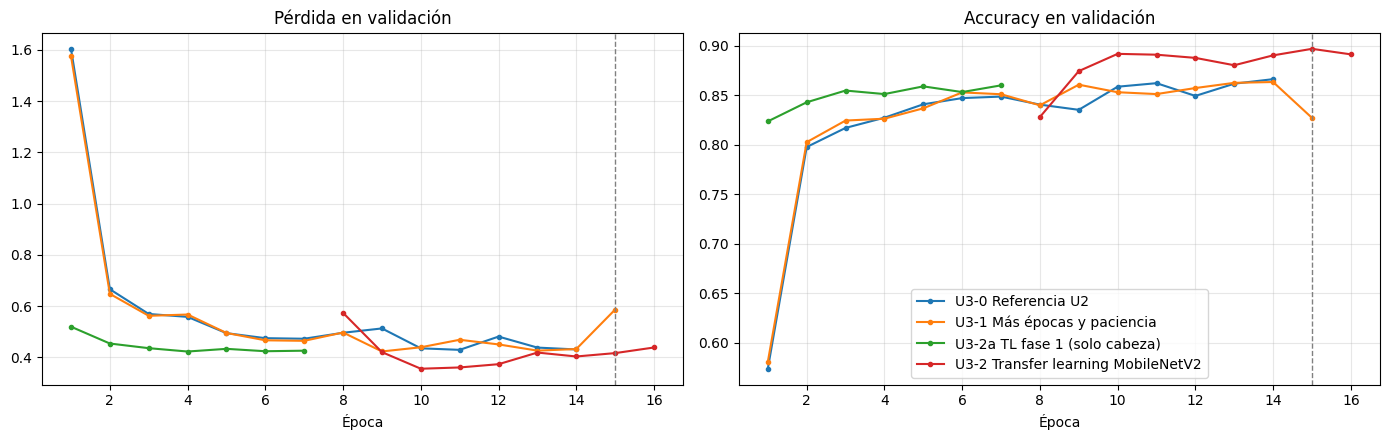

In [20]:
# Curvas de validación; la línea punteada marca el límite de 15 épocas de la Unidad 2
os.makedirs("artefactos/unidad3/figuras", exist_ok=True)
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
for nombre, h in historiales.items():
    inicio = len(historiales[FASE1]["val_loss"]) if nombre == TL else 0   # la fase 2 continúa la fase 1
    x_epocas = np.arange(1, len(h["val_loss"]) + 1) + inicio
    for eje, metrica in zip(ejes, ["val_loss", "val_accuracy"]):
        eje.plot(x_epocas, h[metrica], marker="o", markersize=3, linewidth=1.5, label=nombre)
for eje, titulo in zip(ejes, ["Pérdida en validación", "Accuracy en validación"]):
    eje.axvline(EPOCAS_U2, color="gray", linestyle="--", linewidth=1)
    eje.set(title=titulo, xlabel="Época")
    eje.grid(alpha=0.3)
ejes[1].legend()
plt.tight_layout()
plt.savefig("artefactos/unidad3/figuras/curvas_validacion_u3.png", dpi=150, bbox_inches="tight")
plt.show()

## Evaluación en prueba del mejor experimento

Solo el experimento con mejor F1-macro en validación se evalúa en prueba, una sola vez, para compararlo con el modelo aprobado de la Unidad 2, que en prueba obtuvo F1-macro 0.8005 y accuracy 0.8578. La última celda guarda sus resultados en `artefactos/unidad3/` y los descarga como `resultados_u3.zip`. No toca los archivos del modelo aprobado (`artefactos/modelo_final.keras`, `clases.json`, `metricas.json`, `historial.json`): al descomprimir el zip en la raíz del repositorio, cada archivo queda en `artefactos/unidad3/`.

In [21]:
modelo_final = modelos[ELEGIDO]
y_test = test_gen.classes
y_pred_test = modelo_final.predict(test_gen, verbose=0).argmax(axis=1)
metricas_prueba = {
    "n_prueba": int(len(y_test)),
    "accuracy": accuracy_score(y_test, y_pred_test),
    "f1_macro": f1_score(y_test, y_pred_test, average="macro"),
    "f1_weighted": f1_score(y_test, y_pred_test, average="weighted"),
}
print(f"Prueba · {ELEGIDO}: F1-macro={metricas_prueba['f1_macro']:.4f} | "
      f"accuracy={metricas_prueba['accuracy']:.4f} | F1-weighted={metricas_prueba['f1_weighted']:.4f}")
print(classification_report(y_test, y_pred_test, target_names=NOMBRES_CLASES, digits=3, zero_division=0))

# Confusiones más frecuentes en prueba
cm = confusion_matrix(y_test, y_pred_test, labels=range(NUM_CLASES))
np.fill_diagonal(cm, 0)
pares = [(NOMBRES_CLASES[i], NOMBRES_CLASES[j], cm[i, j])
         for i in range(NUM_CLASES) for j in range(NUM_CLASES) if cm[i, j]]
display(pd.DataFrame(pares, columns=["clase_real", "clase_predicha", "imagenes"])
        .sort_values("imagenes", ascending=False).head(10))

Prueba · U3-2 Transfer learning MobileNetV2: F1-macro=0.8402 | accuracy=0.8861 | F1-weighted=0.8830
                       precision    recall  f1-score   support

            Backpacks      0.878     0.935     0.906       108
                Belts      1.000     1.000     1.000       122
                  Bra      1.000     0.958     0.978        71
               Briefs      0.992     1.000     0.996       127
                 Caps      1.000     0.857     0.923        42
         Casual Shoes      0.867     0.780     0.821       427
             Clutches      0.955     0.488     0.646        43
            Deodorant      0.927     0.981     0.953        52
              Dresses      0.702     0.894     0.787        66
             Earrings      0.984     0.984     0.984        62
                Flats      0.460     0.307     0.368        75
           Flip Flops      0.794     0.891     0.840       138
         Formal Shoes      0.867     0.895     0.881        95
             Hand

,clase_real,clase_predicha,imagenes
14,Casual Shoes,Sports Shoes,66
125,Tshirts,Tops,53
109,Tops,Tshirts,40
28,Flats,Heels,34
87,Sports Shoes,Casual Shoes,28
40,Heels,Flats,18
74,Sandals,Flip Flops,15
18,Clutches,Wallets,15
122,Tshirts,Shirts,15
107,Tops,Shirts,15


In [22]:
# Resultados de la Unidad 3 en artefactos/unidad3/. No se sobrescriben los archivos del modelo aprobado
# (artefactos/modelo_final.keras, clases.json, metricas.json, historial.json), que usan la app y la página web.
CARPETA_U3 = "artefactos/unidad3"
SUFIJO = "mobilenetv2" if ELEGIDO == TL else "cnn_u3"
os.makedirs(CARPETA_U3, exist_ok=True)
modelo_final.save(f"{CARPETA_U3}/{SUFIJO}.keras")
archivos = {
    f"metricas_prueba_{SUFIJO}.json": metricas_prueba,
    f"metricas_validacion_{SUFIJO}.json": {"accuracy": resultados[ELEGIDO]["val_acc"],
                                           "f1_macro": resultados[ELEGIDO]["val_F1_macro"],
                                           "f1_weighted": resultados[ELEGIDO]["val_F1_weighted"]},
    "historiales_u3.json": historiales,
}
for nombre, contenido in archivos.items():
    with open(f"{CARPETA_U3}/{nombre}", "w", encoding="utf-8") as f:
        json.dump(contenido, f, ensure_ascii=False, indent=2)
tabla.to_csv(f"{CARPETA_U3}/experimentos_u3.csv")
reporte = classification_report(y_test, y_pred_test, target_names=NOMBRES_CLASES,
                                output_dict=True, zero_division=0)
pd.DataFrame(reporte).T.to_csv(f"{CARPETA_U3}/reporte_por_clase_{SUFIJO}.csv")
pd.DataFrame(confusion_matrix(y_test, y_pred_test, labels=range(NUM_CLASES)),
             index=NOMBRES_CLASES, columns=NOMBRES_CLASES).to_csv(f"{CARPETA_U3}/matriz_confusion_{SUFIJO}.csv")

# Al descomprimir el zip en la raíz del repositorio, todo queda en artefactos/unidad3/
!zip -qr resultados_u3.zip artefactos/unidad3
from google.colab import files
files.download("resultados_u3.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Análisis de resultados de la Unidad 3

**Comparación en validación** (misma partición, mismos generadores, semilla 42):

| Modelo | F1-macro | Accuracy | Épocas (mejor) | Δ F1 vs. modelo U2 |
|---|---|---|---|---|
| Modelo seleccionado en la U2 (CNN, `lr = 1e-4`, 15 épocas, paciencia 3) | 0.8112 | 0.8621 | 14 (11) | — |
| Mejora #2: misma CNN con 40 épocas y paciencia 6 | 0.8084 | 0.8605 | 15 (9) | −0.0028 |
| Mejora #4, fase 1: MobileNetV2 congelada (solo la capa de salida) | 0.8038 | 0.8511 | 7 (4) | −0.0074 |
| **Mejora #4: MobileNetV2 preentrenada y ajustada** | **0.8519** | **0.8916** | 9 (3) | **+0.0407** |

**Mejora #2 (más épocas y paciencia): en esta corrida no mejoró al modelo seleccionado.**

- Con paciencia 6, EarlyStopping detuvo la CNN en la época 15 (mejor `val_loss` en la 9), así que el máximo de 40 épocas nunca se usó. En la práctica, la corrida evaluó la paciencia, no el número de épocas.
- La diferencia con el modelo de la Unidad 2 (−0.003) es menor que la variación entre semillas (±0.0055): los dos son equivalentes.
- La conclusión válida es acotada: con `lr = 1e-4` y una sola semilla, esperar más épocas sin mejora no ayudó. No permite afirmar que entrenar más épocas no ayude.
- La referencia de esta sesión (0.8112) queda dentro del rango medido en la Unidad 2 (0.8168 ± 0.0055).

**Mejora #4 (MobileNetV2 preentrenada): mejor desempeño.** El F1-macro de validación sube +0.041, unas siete veces la variación entre semillas, así que la diferencia no se explica por el azar.

- Solo con la red congelada (fase 1), las características de ImageNet igualan a la CNN entrenada desde cero (0.804 frente a 0.811). El ajuste fino de los bloques superiores aporta casi toda la mejora.
- El ajuste fino alcanza su mejor época muy pronto (la 3); después el `val_loss` sube de 0.356 a 0.438. Lo que importa es restaurar la mejor época, no entrenar más.

**Comparación en prueba** (una sola evaluación del mejor experimento):

| Métrica | Modelo seleccionado en la U2 | Mejora #4: MobileNetV2 | Diferencia |
|---|---|---|---|
| F1-macro | 0.8005 | 0.8402 | +0.040 |
| Accuracy | 0.8578 | 0.8861 | +0.028 |
| F1-weighted | 0.8528 | 0.8830 | +0.030 |

**Errores que persisten.**

- **Clases más débiles en los dos modelos:** *Tunics*, *Flats* y *Kurtis* (con MobileNetV2, F1 de 0.22, 0.37 y 0.37).
- **Confusiones más frecuentes:** Casual Shoes → Sports Shoes, Tshirts ↔ Tops y Flats → Heels. Son productos que se diferencian por detalles finos o por definiciones de categoría que se solapan.
- Esto apoya la mejora #3 pendiente: revisar con negocio esas definiciones o agrupar clases.

**Decisión.** El modelo seleccionado en la Unidad 2 **se mantiene como modelo aprobado**: es el que usan la aplicación, la página web y el pipeline. MobileNetV2 tiene mejor desempeño y, para avances futuros, se puede evaluar como la **arquitectura preferida** hasta convertirse en el modelo predefinido. Antes de ese cambio conviene:

- confirmar el resultado con semillas adicionales;
- medir su costo en la aplicación (2.3 millones de parámetros y unos 9 MB de pesos, frente a 1.25 millones y 5 MB de la CNN);
- revisar con negocio las clases confundidas.

El modelo MobileNetV2 entrenado y sus métricas quedan en `artefactos/unidad3/`. La conversión a TensorFlow.js de ambos modelos se verificó sobre las 5,916 imágenes de prueba y reproduce exactamente las métricas de Keras.

**Limitaciones.**

- Los experimentos se corrieron con una sola semilla, por tiempo de cómputo.
- La mejora #2 no llegó a usar el presupuesto de 40 épocas. Para evaluar de verdad más épocas haría falta otra corrida, por ejemplo bajando la tasa de aprendizaje cuando el `val_loss` se estanca (`ReduceLROnPlateau`).
- La entrada sigue siendo de 80 × 60: el reescalado a 160 × 120 dentro de MobileNetV2 no agrega información.